In [1]:
import os
from typing import Annotated, Sequence, TypedDict
from dotenv import load_dotenv

from langchain.chat_models import init_chat_model
from langchain.agents import create_agent                      # create_react_agent ka naya version
from langchain_core.tools import Tool                          # langchain.agents.Tool ab yahan hai
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_huggingface import HuggingFaceEmbeddings        # OpenAIEmbeddings ki jagah
from langchain_community.vectorstores import FAISS
from langchain_community.document_loaders import WebBaseLoader, TextLoader
from langchain_community.utilities import WikipediaAPIWrapper, ArxivAPIWrapper
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

C:\Users\Adit Sharma\AppData\Local\Temp\ipykernel_2356\1441902505.py:10: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS
USER_AGENT environment variable not set, consider setting it to identify your requests.


In [2]:
load_dotenv()
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY") or os.getenv("groq_api", "")
os.environ["HF_TOKEN"] = os.getenv("HF_TOKEN") or os.getenv("hf_token", "")
os.environ["USER_AGENT"] = "react-rag-notebook"   # WebBaseLoader ki warning band karne ke liye

import wikipedia
wikipedia.set_user_agent("RAG-ReAct-Notebook/1.0 (learning project)")   # warna Wikipedia 429 de deta hai

import socket
socket.setdefaulttimeout(30)   # wikipedia/arxiv libraries khud timeout nahi lagati – network atka toh cell hang na ho

llm = init_chat_model("groq:openai/gpt-oss-20b", temperature=0)
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.0', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000018C710F01A0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000018C710F0EC0>, model_name='openai/gpt-oss-20b', temperature=1e-08, model_kwargs={}, groq_api_key=SecretStr('**********'))

In [3]:
docs = WebBaseLoader("https://lilianweng.github.io/posts/2023-06-23-agent/").load()
chunks = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50).split_documents(docs)

embedding = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")
vectorstore = FAISS.from_documents(chunks, embedding)
retriever = vectorstore.as_retriever()

retriever.invoke("what are autonomous agents")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

[Document(id='f70cb35b-9802-40d5-9e03-4c4a4f977a4f', metadata={'source': 'https://lilianweng.github.io/posts/2023-06-23-agent/', 'title': "LLM Powered Autonomous Agents | Lil'Log", 'description': 'Building agents with LLM (large language model) as its core controller is a cool concept. Several proof-of-concepts demos, such as AutoGPT, GPT-Engineer and BabyAGI, serve as inspiring examples. The potentiality of LLM extends beyond generating well-written copies, stories, essays and programs; it can be framed as a powerful general problem solver.\nAgent System Overview\nIn a LLM-powered autonomous agent system, LLM functions as the agent’s brain, complemented by several key components:\n\nPlanning\n\nSubgoal and decomposition: The agent breaks down large tasks into smaller, manageable subgoals, enabling efficient handling of complex tasks.\nReflection and refinement: The agent can do self-criticism and self-reflection over past actions, learn from mistakes and refine them for future steps, 

In [4]:
def retriever_tool_func(query: str) -> str:
    print("📚 Using RAGRetriever tool")
    docs = retriever.invoke(query)
    return "\n".join(doc.page_content for doc in docs)

retriever_tool = Tool(
    name="RAGRetriever",
    description="Use this tool to fetch relevant knowledge base info about LLM-powered autonomous agents (planning, memory, tool use).",
    func=retriever_tool_func,
)

print(retriever_tool.name)
print(retriever_tool.invoke("what are autonomous agents")[:300])

RAGRetriever
📚 Using RAGRetriever tool
Building agents with LLM (large language model) as its core controller is a cool concept. Several proof-of-concepts demos, such as AutoGPT, GPT-Engineer and BabyAGI, serve as inspiring examples. The potentiality of LLM extends beyond generating well-written copies, stories, essays and programs; it c


In [5]:
wiki_api = WikipediaAPIWrapper(top_k_results=1, doc_content_chars_max=1500)

def wiki_search(query: str) -> str:
    print("🌐 Using Wikipedia tool")
    try:
        return wiki_api.run(query)
    except Exception as e:
        return f"Wikipedia search failed ({e.__class__.__name__}). Answer from other sources."

wiki_tool = Tool(
    name="Wikipedia",
    description="Use this tool to fetch general world knowledge from Wikipedia.",
    func=wiki_search,
)

print(wiki_tool.invoke("autonomous agent")[:300])

🌐 Using Wikipedia tool
Page: Autonomous agent
Summary: An autonomous agent is an artificial intelligence (AI) system that can perform complex tasks independently.


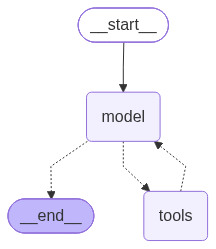

In [6]:
tools = [retriever_tool, wiki_tool]
react_node = create_agent(llm, tools)
react_node

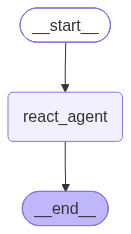

In [7]:
class AgentState(TypedDict):
    messages: Annotated[Sequence[BaseMessage], add_messages]

builder = StateGraph(AgentState)
builder.add_node("react_agent", react_node)
builder.add_edge(START, "react_agent")
builder.add_edge("react_agent", END)

graph = builder.compile()
graph

In [8]:
user_query = "What is an agent loop and how does Wikipedia describe autonomous agents?"
result = graph.invoke({"messages": [HumanMessage(content=user_query)]})

print("\n✅ Final Answer:\n", result["messages"][-1].content)

🌐 Using Wikipedia tool
🌐 Using Wikipedia tool
🌐 Using Wikipedia tool
🌐 Using Wikipedia tool
🌐 Using Wikipedia tool
🌐 Using Wikipedia tool

✅ Final Answer:
 **Agent Loop**

An *agent loop* (sometimes called a *control loop* or *perception‑action loop*) is the basic iterative cycle that an autonomous system follows to interact with its environment.  In the context of AI‑powered agents, the loop typically consists of the following stages:

| Step | What happens | Typical tools / components |
|------|--------------|---------------------------|
| **1. Perception** | The agent receives sensory input (text, images, sensor data, etc.). | LLM prompt, vision models, sensor APIs |
| **2. State Update / Memory** | The agent updates its internal state or memory with the new information. | Structured memory store, context window, knowledge graph |
| **3. Planning / Decision‑Making** | The agent decides what to do next, often by generating a plan or a set of actions. | LLM reasoning, planner modules,

In [9]:
# Andar kya hua – Human → AI (tool calls) → Tool outputs → AI (final answer)
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is an agent loop and how does Wikipedia describe autonomous agents?
================================== Ai Message ==================================
Tool Calls:
  Wikipedia (fc_84217235-34d4-483b-a720-149d9ea7bc5a)
 Call ID: fc_84217235-34d4-483b-a720-149d9ea7bc5a
  Args:
    __arg1: agent loop
================================= Tool Message =================================
Name: Wikipedia

Page: Agent harness
Summary: An agent harness, also known as agent scaffolding, is the software infrastructure surrounding a large language model (LLM) that enables it to operate as an AI agent. It manages tool use, memory, state persistence, execution environments and feedback loops, as opposed to the model's internal reasoning. The UK's AI Security Institute described an AI agent as being formed by the model plus the scaffolding back in 2023.  The relationship can be expressed as agent = model + harness.
Because

In [10]:
def make_retriever_tool_from_text(file, name, desc):
    docs = TextLoader(file, encoding="utf-8").load()
    chunks = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50).split_documents(docs)
    vs = FAISS.from_documents(chunks, embedding)    # upar wala HF embedding reuse
    retriever = vs.as_retriever(search_kwargs={"k": 3})

    def tool_func(query: str) -> str:
        print(f"📚 Using tool: {name}")
        results = retriever.invoke(query)
        return "\n\n".join(doc.page_content for doc in results)

    return Tool(name=name, description=desc, func=tool_func)

In [11]:
arxiv_wrapper = ArxivAPIWrapper(top_k_results=2, doc_content_chars_max=2000)

def arxiv_search(query: str) -> str:
    print("🧪 Searching ArXiv...")
    try:
        return arxiv_wrapper.run(query) or "No papers found."
    except Exception as e:
        # ArXiv jaldi-jaldi calls pe 429 (rate limit) deta hai. Crash karne ki jagah
        # agent ko text mein bata do – woh baaki tools se answer bana lega.
        return f"ArXiv search failed ({e.__class__.__name__}). Try again later or answer from other sources."

arxiv_tool = Tool(
    name="ArxivSearch",
    description="Use this tool to fetch recent academic papers on technical topics.",
    func=arxiv_search,
)

In [12]:
internal_tool_1 = make_retriever_tool_from_text(
    "internal_docs.txt",
    "InternalTechDocs",
    "Search internal tech documents for proprietary architecture and methods.",
)

internal_tool_2 = make_retriever_tool_from_text(
    "research_notes.txt",
    "InternalResearchNotes",
    "Search internal research notes for experimental results and agent designs.",
)

print(internal_tool_2.invoke("transformer variants"))

📚 Using tool: InternalResearchNotes
Experiment 14: Transformer variants for long documents
We compared a standard Transformer, Longformer and a Mixture-of-Experts (MoE) Transformer on our 8k-token contract summarisation dataset.
Longformer's sliding-window attention reduced memory use by 45 percent compared to full attention, with only a 1.2 point drop in ROUGE-L.
The MoE variant (8 experts, top-2 routing) gave the best ROUGE-L score (+2.1 over baseline) but training was unstable without a load-balancing loss.

Conclusion: use Longformer for cost-sensitive workloads and MoE when quality matters most.

Internal Research Notes - Applied ML Team


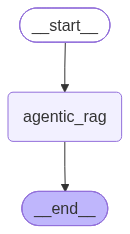

In [13]:
tools = [wiki_tool, arxiv_tool, internal_tool_1, internal_tool_2]
react_node = create_agent(
    llm,
    tools,
    system_prompt="You are a research assistant. Use the internal tools for company-specific questions "
                  "and Wikipedia/ArXiv for public knowledge. Say which source each fact came from.",
)

builder = StateGraph(AgentState)
builder.add_node("agentic_rag", react_node)
builder.add_edge(START, "agentic_rag")
builder.add_edge("agentic_rag", END)

graph = builder.compile()
graph

In [14]:
query = "What do our internal research notes say about transformer variants, and what does ArXiv suggest recently?"
result = graph.invoke({"messages": [HumanMessage(content=query)]})

print("\n✅ Final Answer:\n", result["messages"][-1].content)

📚 Using tool: InternalResearchNotes
🧪 Searching ArXiv...
🧪 Searching ArXiv...

✅ Final Answer:
 **Internal Research Notes (Applied ML Team)**  
*Experiment 14 – Transformer variants for long‑document summarisation*  

| Variant | Key Findings | Practical Take‑away |
|---------|--------------|---------------------|
| **Longformer** (sliding‑window attention) | • 45 % reduction in memory usage vs. full‑attention. <br>• Only a 1.2‑point drop in ROUGE‑L on our 8 k‑token contract‑summarisation dataset. | Use Longformer when inference cost or GPU memory is a constraint. |
| **Mixture‑of‑Experts (MoE)** (8 experts, top‑2 routing) | • Best ROUGE‑L (+2.1 over baseline). <br>• Training unstable without a load‑balancing loss. | Deploy MoE when the highest summarisation quality is required and you can afford the extra training complexity. |

**Conclusion from the notes** – *Longformer* is the go‑to for cost‑sensitive workloads; *MoE* is preferable when quality is paramount and you can manage the t

In [15]:
query = "How does our Nimbus system do retrieval, and which agent design worked best in our experiments?"
result = graph.invoke({"messages": [HumanMessage(content=query)]})

# Sirf dekhna hai ki kaunse tools bulaye gaye
for m in result["messages"]:
    for tc in getattr(m, "tool_calls", []) or []:
        print("🔧", tc["name"], "->", tc["args"])

print("\n✅ Final Answer:\n", result["messages"][-1].content)

📚 Using tool: InternalTechDocs
📚 Using tool: InternalResearchNotes
🔧 InternalTechDocs -> {'__arg1': 'Nimbus retrieval mechanism'}
🔧 InternalResearchNotes -> {'__arg1': 'Nimbus agent design experiments'}

✅ Final Answer:
 **Nimbus Retrieval**

Nimbus uses a *hybrid retrieval stack* that combines dense‑vector search with keyword‑based search:

| Component | Details | Source |
|-----------|---------|--------|
| **Dense index** | FAISS index built with the `all-MiniLM-L6-v2` embedding model | InternalTechDocs |
| **Keyword index** | BM25 index over the same document chunks | InternalTechDocs |
| **Score fusion** | Reciprocal Rank Fusion (RRF) merges the two retrieval scores | InternalTechDocs |
| **Reranking** | Cross‑encoder `ms-marco-MiniLM-L-6-v2` reranks the top 20 merged results | InternalTechDocs |
| **LLM input** | The top 5 reranked chunks are fed to the LLM, with chunk IDs cited in the answer | InternalTechDocs |

The ingestion layer pulls documents from Confluence, Google Drive, 